# Model training
Trains the gradient-boosted fraud model on engineered features. The reproducible one-command version is `python 3_Model/training/train_model.py`; this notebook walks through it.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "3_Model").exists():
    ROOT = ROOT.parent
for p in ("3_Model", "3_Model/training", "4_Backend/utils"):
    sys.path.insert(0, str(ROOT / p))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"


In [2]:
from preprocessing import FEATURES, FEATURE_LABELS
from train_model import load_dataset, time_split, make_model, evaluate
df = load_dataset()
print(f'{len(df):,} orders, fraud rate {df.is_fraud.mean():.1%}, {len(FEATURES)} features')
df.head()

19,950 orders, fraud rate 7.5%, 21 features


,transaction_id,user_id,device_id,card_hash,timestamp,billing_country,ip_country,is_vpn,is_proxy,country_mismatch,...,pages_viewed,account_age_days,new_account_high_spend,amount,log_amount,amount_to_baseline,users_per_card,hour,is_night,is_fraud
0,T0006048,U00654,D01042,C434555042637,2026-01-01 01:29:00,AU,AU,0,0,0,...,11,400.52,0,28.56,3.3864,0.675,1,1,1,0
1,T0001178,U00725,D01155,C187288266409,2026-01-01 04:14:00,US,US,0,0,0,...,18,238.30,0,29.70,3.4243,0.727,2,4,1,0
2,T0019233,U01745,D02695,C938962963091,2026-01-01 04:24:00,CA,CA,1,0,0,...,20,204.39,0,15.79,2.8208,1.008,1,4,1,0
3,T0003547,U01192,D01869,C703248853124,2026-01-01 05:24:00,MX,MX,0,0,0,...,4,1025.89,0,31.80,3.4904,0.874,1,5,1,0
4,T0014895,U01479,D02296,C575375128395,2026-01-01 05:50:00,US,US,0,0,0,...,1,589.08,0,17.55,2.9205,0.899,1,5,1,0


## Signals: fraud vs legitimate
Median / share of each signal by class. No single signal separates the classes, which is why a model is needed.

In [3]:
df.groupby('is_fraud')[FEATURES].mean().T.rename(columns={0: 'legit', 1: 'fraud'}).round(3)

is_fraud,legit,fraud
is_vpn,0.080,0.412
is_proxy,0.019,0.202
country_mismatch,0.072,0.560
high_risk_country,0.010,0.325
is_emulator,0.013,0.221
is_rooted,0.035,0.234
timezone_mismatch,0.044,0.328
accounts_per_device,1.215,6.870
login_attempts,1.350,2.291
failed_logins,0.055,0.558


## Time-based split
Train on the past, test on the most recent 20% - the way the model is used in production.

In [4]:
train, test = time_split(df)
print(train.timestamp.max(), '->', test.timestamp.min())
model = make_model().fit(train[FEATURES], train.is_fraud)
evaluate(model, test)

2026-08-22 18:32:00 -> 2026-08-22 18:36:00


{'roc_auc': 0.9975,
 'pr_auc': 0.98,
 'review': {'threshold': 30,
  'precision': 0.8913,
  'recall': 0.9647,
  'f1': 0.9266,
  'flag_rate': 0.0692,
  'confusion': {'tn': 3705, 'fp': 30, 'fn': 9, 'tp': 246}},
 'block': {'threshold': 70,
  'precision': 0.9333,
  'recall': 0.9333,
  'f1': 0.9333,
  'flag_rate': 0.0639,
  'confusion': {'tn': 3718, 'fp': 17, 'fn': 17, 'tp': 238}},
 'fraud_dollars_in_test': 57444.32,
 'fraud_dollars_flagged': 56787.57,
 'n_test': 3990,
 'test_fraud_rate': 0.0639}

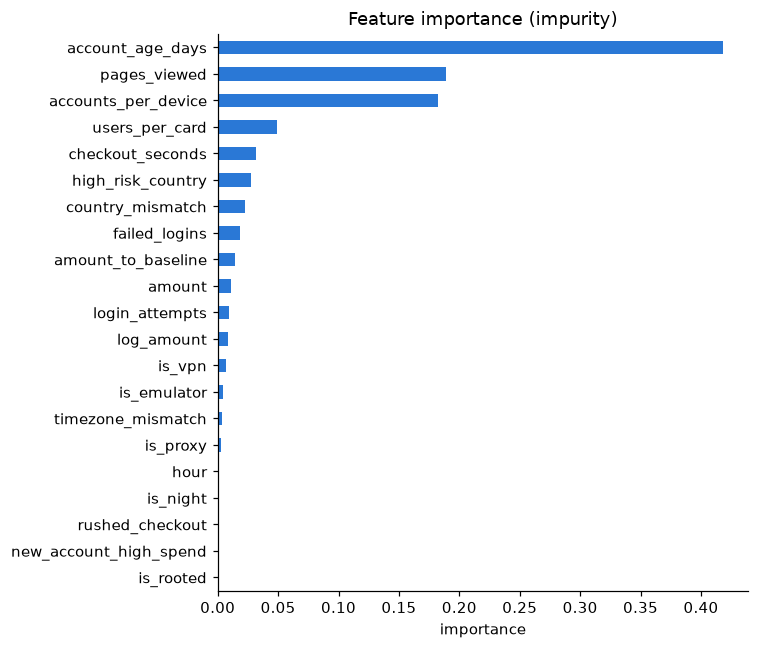

In [5]:
imp = pd.Series(model.feature_importances_, index=FEATURES).sort_values()
ax = imp.plot.barh(color=BLUE, figsize=(7, 6), title='Feature importance (impurity)')
ax.set_xlabel('importance'); plt.tight_layout()

## Save the bundle
`train()` refits and writes `saved_models/fraud_model.pkl` with the model, feature list, legit baselines (for explanations), thresholds and metrics.

In [6]:
from train_model import train
bundle = train()
bundle['version'], bundle['metrics']['pr_auc']

('gbm-20261106-0450', 0.98)